# Plotting for article
We start by importing all the libraries we are going to use. 

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os
import math
from scipy.signal import butter, filtfilt, welch, detrend
from scipy.stats import chi2

Here we define the sample frequency, the data directory and files of interest and missing files. Skip

In [18]:
fs = 10 # Hz
src_file = f"data/F00"
tags = [" AccNED1", " AccNED2", " ACCNED3"]
start = 204
stop  = 346
foi = [291, 312, 335]
# Some files have missing data, and needs to be skipped
ignore_list = [208,210, 223,226,237, 250, 262, 265, 270,296,299,301,309, 313,315, 320, 325, 333, 334]
out_dir = "pics/"
np.seterr(divide='ignore')
skip_n = 500
os.system("mkdir figures")

mkdir: cannot create directory ‘figures’: File exists


256

We also set the text size of the legends, titles and labels.


In [19]:
MEDIUM_SIZE = 22
SMALL_SIZE  = MEDIUM_SIZE - 3
BIGGER_SIZE = MEDIUM_SIZE + 3
plt.rc('axes',labelsize=MEDIUM_SIZE)
plt.rc('axes', titlesize=SMALL_SIZE)
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title
plt.rc("xtick", labelsize=SMALL_SIZE)
plt.rc("ytick", labelsize=SMALL_SIZE)
plt.rc("legend", fontsize=SMALL_SIZE)

Now, we include a function ```analyse_IMU_file``` from ```analyze_IMU_file.py``` which extracts all relevant data from an IMU file, and computes wavestatistics like the significant waveheight  $H_s$ and the peak period $T_p$.

In [20]:
from analyze_IMU_file import analyse_IMU_file


We now extract the accelerations from the files of interest, and the wavestatistics from all the files. Furthermore, we find the internal temperature of the buoy.

In [21]:
accz = []
accy = []
accx = []
SWH = np.zeros(stop - start + 1)
Tp  = SWH.copy()
ak = SWH.copy()

#Files of interest (FOI) acceleration data extraction
noisy_avg = np.zeros(len(foi))
for i,file_id in enumerate(foi):
    srcf = src_file+str(file_id)
    noisy_avg[i], std_noise, SWH_, Tp_, ak_, detrended_vert, filtered_ac,t, aX, aY, aZ, eta, temp = analyse_IMU_file(srcf, file_id, tags,  out_dir, fs, skip_n)
    accz.append(aZ)
    accx.append(aX)
    accy.append(aY)

# Internal temperature array
T0s = []
files_id = []
temp291 = []
for i in range(start, stop+1):
    srcf = src_file+str(i)
    if i in ignore_list:
      SWH[i - start] = math.nan
      Tp[i-start]    = math.nan
      ak[i - start]  = math.nan
    else:
      noisy_avg_, std_noise_, SWH[i-start], Tp[i-start], ak[i-start], detrended_vert_, filtered_ac_,t_, aX_, aY_, aZ_, eta, temp \
          = analyse_IMU_file(srcf, i, tags,  out_dir, fs, skip_n)
      
      # Temperature plotting
      T0s.append(np.average(temp[0:100]))
      if (i == 291):
         temp291 = temp
      files_id.append(i)
      


We then plot the internal temperature of the buoy


<>:2: SyntaxWarning: invalid escape sequence '\c'
<>:2: SyntaxWarning: invalid escape sequence '\c'
/tmp/ipykernel_18609/3574155155.py:2: SyntaxWarning: invalid escape sequence '\c'
  fig.supylabel("Temperature [$^\circ$C]", x =0.05)


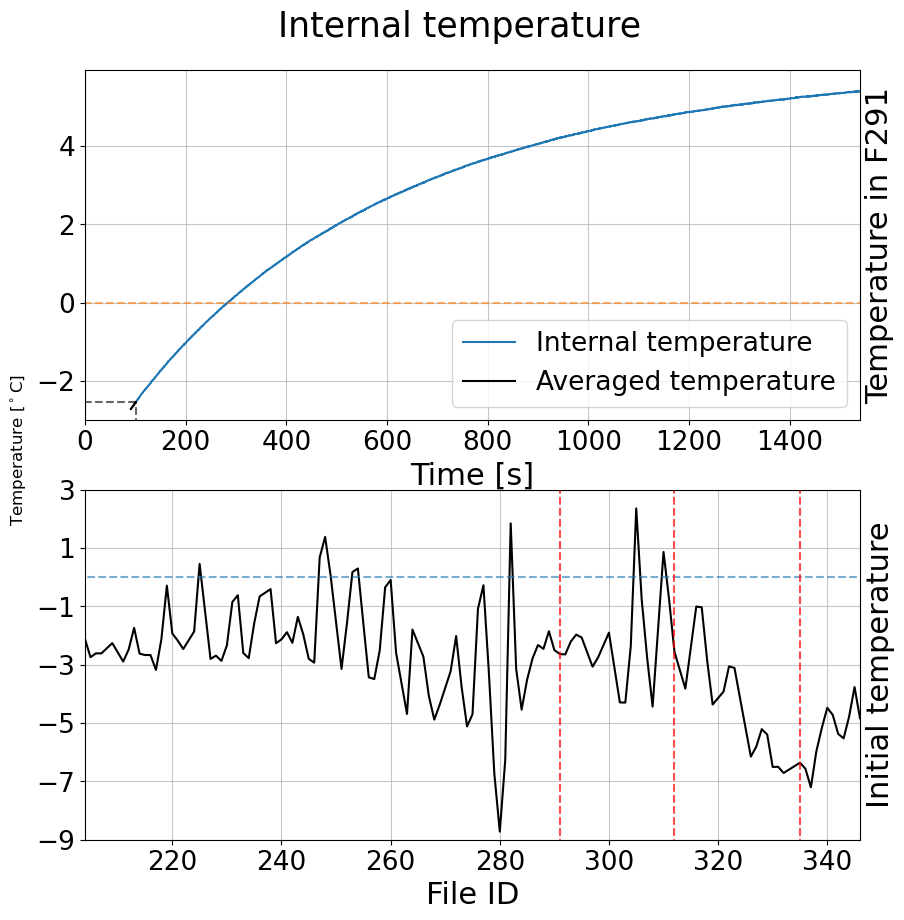

In [22]:

fig, axs = plt.subplots(2,1, figsize=(10,10))
fig.supylabel("Temperature [$^\circ$C]", x =0.05)

# Temp in one selected file
axs[0].plot(t_[100:], temp291[100:len(t_)], linewidth=1.5, label="Internal temperature")
axs[0].plot(t_[:100], temp291[:100], color='black',linewidth=1.5, label="Averaged temperature")
axs[0].yaxis.set_label_position("right")
axs[0].set_ylabel("Temperature in F291")
axs[0].set_xlabel("Time [s]")
axs[0].grid(alpha=0.7)
axs[0].plot(np.linspace(-1,2000, 500), np.zeros(500), linestyle='dashed', alpha=0.6)
axs[0].plot(np.linspace(-1, t_[100], 100), temp291[100]*np.ones(100), linestyle="dashed", color="black", alpha=0.6)
axs[0].plot(t_[100]*np.ones(100), np.linspace(-4, temp291[100], 100) , linestyle="dashed", color="black", alpha=0.6)
axs[0].set_xlim([0, t_[-1]])
axs[0].set_ylim([1.1*np.amin(temp291), 1.1*np.amax(temp291)])
axs[0].legend()

# Average temperature across all files
axs[1].plot(files_id, T0s, color='black')
axs[1].plot(np.linspace(-1,2000, 500), np.zeros(500), linestyle='dashed', alpha=0.6)
axs[1].set_xlabel("File ID")
axs[1].grid(alpha=0.7)
axs[1].yaxis.set_label_position("right")
axs[1].set_ylabel(f"Initial temperature")
for fileID in foi:
  axs[1].plot(fileID*np.ones(500), np.linspace(-10, 10, 500) , linestyle='dashed', color='red', alpha=0.7)
fig.suptitle("Internal temperature", y=0.94)

axs[1].set_xlim([start,stop])
axs[1].set_ylim([-9,3])
axs[1].set_yticks([-9,-7, -5, -3, -1, 1, 3])
fig.savefig(f"figures/temp.png")
plt.show()

## Filtering algorithm
Choosing a "rigorous" cutoff frequency. Little activity in signal after $f = 0.3$ Hz, which we chose as a cutoff frequency

[-2.44086169e-07 -2.65043677e-07  6.98769940e-07]


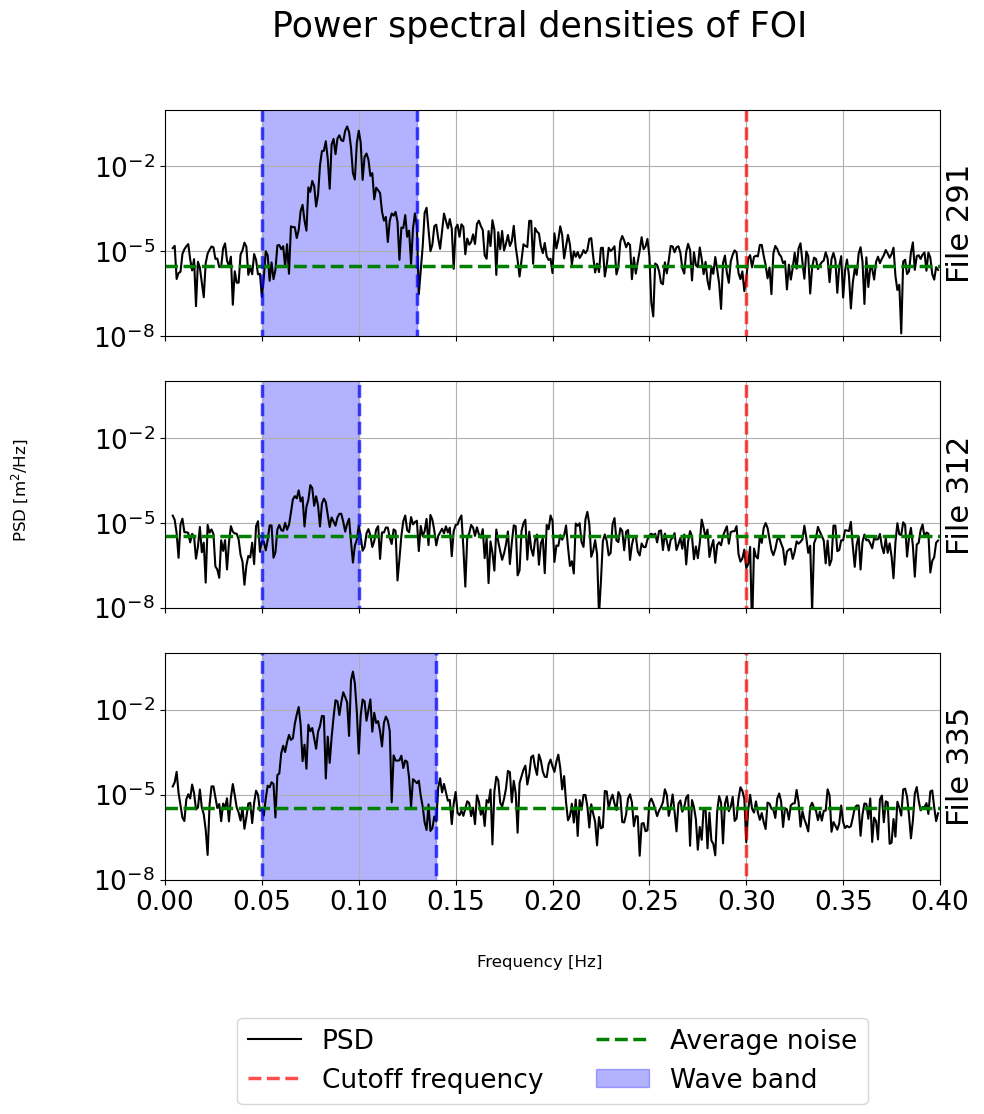

In [23]:
Nt = len(t)
print(noisy_avg)
cutoffs = np.zeros(len(foi), dtype=int)

"""

#Uncomment for raw acceleration data figures

for i in range(len(foi)):
    aZ = np.array(accz[i][:])
    plt.plot(t,aZ[:Nt])
    plt.xlabel("Time [s]")
    plt.ylabel("Acceleration [m/s$^2$]")
    plt.title(f"Vertical acceleration in F{i}")
    plt.savefig(f"figures/accZF{i}.pdf")
    plt.show()
"""

fig, axs = plt.subplots(len(foi), sharex=True, figsize=(10,10))
fig.supxlabel("Frequency [Hz]", y=0.02)
fig.suptitle("Power spectral densities of FOI")
fig.supylabel("PSD [m$^2$/Hz]", x =-0.03)
wavelims = [[0.05, 0.13],[0.05,0.1],[0.05,0.14]]
for i in range(len(foi)):
  aZ = np.array(accz[i][:])
  f,psdN = welch(aZ, fs, nperseg=1e4)
  f = f[4:]
  psdN = psdN[4:]
  axs[i].semilogy(f[f < 0.4], psdN[f < 0.4],color="black")
  axs[i].plot(np.ones(50)*0.3, np.linspace(0,1)*50, linestyle="dashed", color="red", alpha=0.7, linewidth=2.5)
  axs[i].set_ylim([1e-8, 1])
  axs[i].set_xlim([0,0.4])
  axs[i].semilogy(np.linspace(-0.1, 0.5), np.average(psdN[f > 0.3])*np.ones(50), color="green", alpha=1, linestyle="dashed", linewidth=2.5)
  axs[i].fill_betweenx(np.linspace(0,1)*50, np.ones(50)*wavelims[i][0],np.ones(50)*wavelims[i][1], color="blue", alpha=0.3)
  for lims in wavelims[i]:
      axs[i].plot(np.ones(50)*lims, np.linspace(0,1)*50, linestyle="dashed", color="blue", alpha=0.7, linewidth=2.5)
  axs[i].yaxis.set_label_position("right")
  axs[i].set_ylabel(f"File {foi[i]}")
  axs[i].grid()
axs[2].legend(["PSD", "Cutoff frequency", "Average noise", "Wave band"], bbox_to_anchor=(0.5,-0.8), ncol=2, borderaxespad=0, loc="center")
plt.savefig(f"figures/figure_3.pdf")
plt.show()


We here define a function which performs the $\chi$-squared test to check for normally distributed data

In [24]:
import scipy.stats as stats

def Pearson(data, nr_bins = 10):
    n,d = data.shape

    Sigmahatinv = np.linalg.inv(np.cov(data, rowvar = False))
    tmp_func = lambda x: (Sigmahatinv @ x) @ x
    chi2s = np.apply_along_axis(tmp_func, 1, data) #Under H_0, norms are chi-square with d degrees of freedom

    K = 0
    for j in range(nr_bins):
        top = stats.chi2.ppf((j+1)/nr_bins, df = d)
        bottom = stats.chi2.ppf(j/nr_bins, df = d)
        Nj = np.sum((chi2s < top)*(chi2s >= bottom))
        K += ((Nj-n/nr_bins)**2)/(n/nr_bins)

    return 1-stats.chi2.cdf(K, df = nr_bins-4)

We define a fifth order butterworth filter to remove the noise from the signal, and print P value for the selected files. 

In [25]:
order = 5
cutoff = 0.3
b, a = butter(order, cutoff, fs=fs, btype='low', analog=False)

for i in range(len(foi)):
    aX = np.array(accx[i][:])
    aY = np.array(accy[i][:])
    filtx = filtfilt(b,a,aX)
    filty = filtfilt(b,a,aY)
    noiseX = aX - filtx
    noiseY = aY - filty
    stdx = np.std(noiseX)
    stdy = np.std(noiseY)
    # Noise << 1 

    data = np.block([[noiseX], [noiseY]]).T
    print(f"P-value for file F{foi[i]}: {Pearson(data)}")
    

P-value for file F291: 0.0
P-value for file F312: 6.495261158812049e-06
P-value for file F335: 0.5635636402340087


## When do collisions happen?
We now plot a scatter plot of the filtered noise (given by signal - filtered signal) 
alongside ellipses showing the 99% and 99.9% probability regions. We first define the function
```generate_scatter_plot``` which you feed two arrays (for the $x$- and $y$-axes respectively) alongside 
an identification number. You can optionally also specify axis labels, a filename, and  the desired probability regions.


In [26]:
def generate_scatter_plots(X, Y, ax,xlim, ylim, pvals=[0.99, 0.999],rotation="horizontal"):
  #Horizontal plane
  x = np.block([[X],[Y]]).T
  mu_hat = np.mean(x,0)
  sigma_hat = np.cov(x, rowvar=False)
  F = lambda x,y: (np.linalg.inv(sigma_hat)@(np.array([x-mu_hat[0], y- mu_hat[1]])))@(np.array([x-mu_hat[0], y- mu_hat[1]]))
  F = np.vectorize(F)
  n = 300
  Ax, Ay = np.meshgrid(0.9*np.linspace(np.amin(X), 1.1*np.amax(X), n), np.linspace(0.9*np.amin(Y), 1.1*np.amax(Y), n))
  levels = [chi2.ppf(pval,df=2) for pval in pvals]
  ax.contour(Ax, Ay, F(Ax,Ay),levels=levels, linestyles=["dashed", "solid"], colors=["black"], linewidths=3)
  minval = min(np.amin(X), np.amin(Y))
  minval = min(0.95*minval, 1.05*minval)
  maxval = max(np.amax(X), np.amax(Y))
  maxval = max(0.95*maxval, 1.05*maxval)
  poi = np.argwhere(F(X,Y) > chi2.ppf(0.999,df=2))
  
  #plt.xlim([-maxval, maxval])
  #plt.ylim([-maxval, maxval])
  plt.xlim(xlim)
  plt.ylim(ylim)
  #plt.colorbar()
  ax.scatter(X,Y, color="lightgrey", alpha=1)
  ax.scatter(X[poi], Y[poi], color="red",alpha=0.9)
  title =ax.set_title(f"F{foi[i]}",rotation=rotation)
  ax.grid()
  return title


Calling the function yields us a scatterplot of all the FOI.


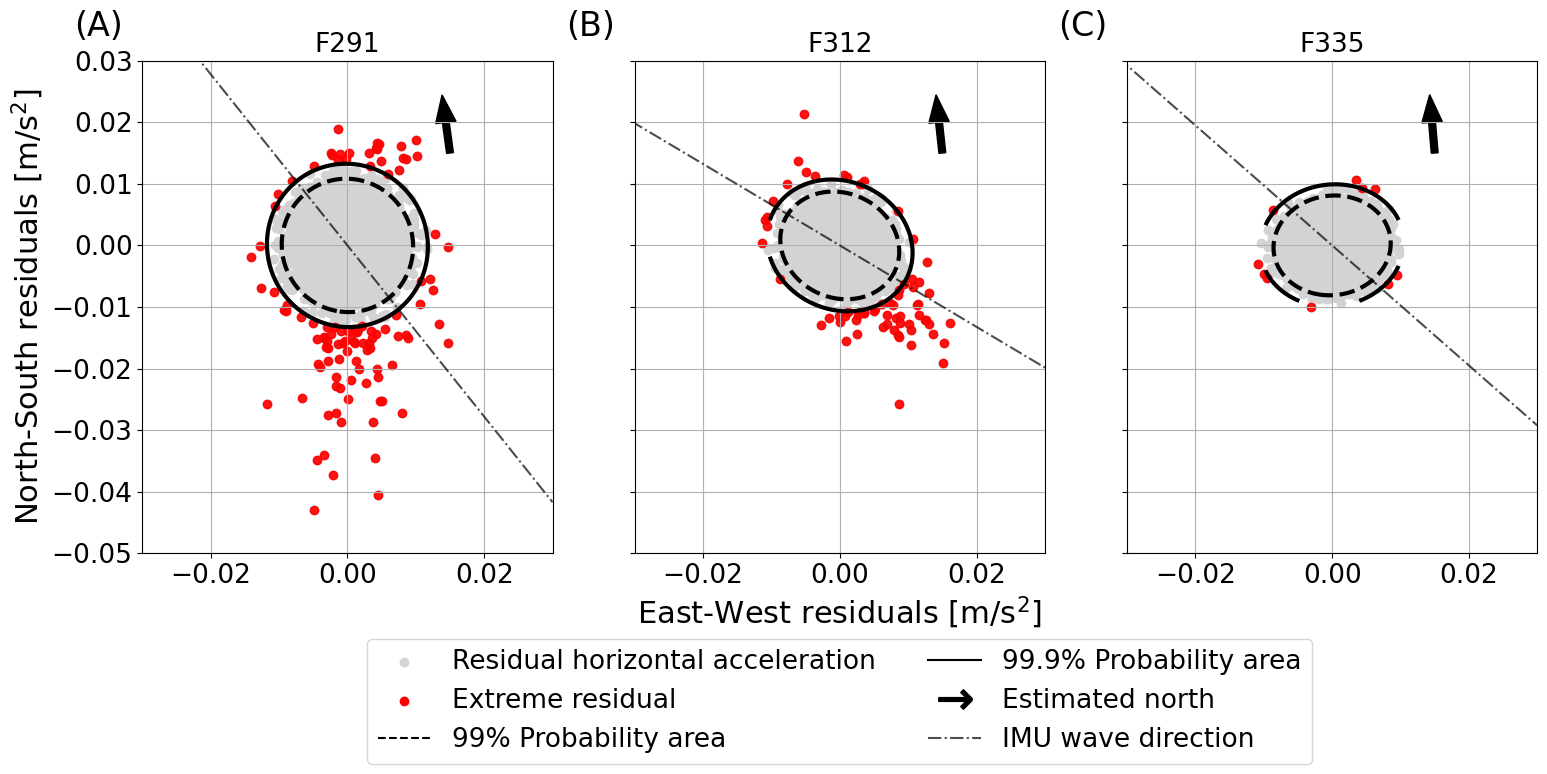

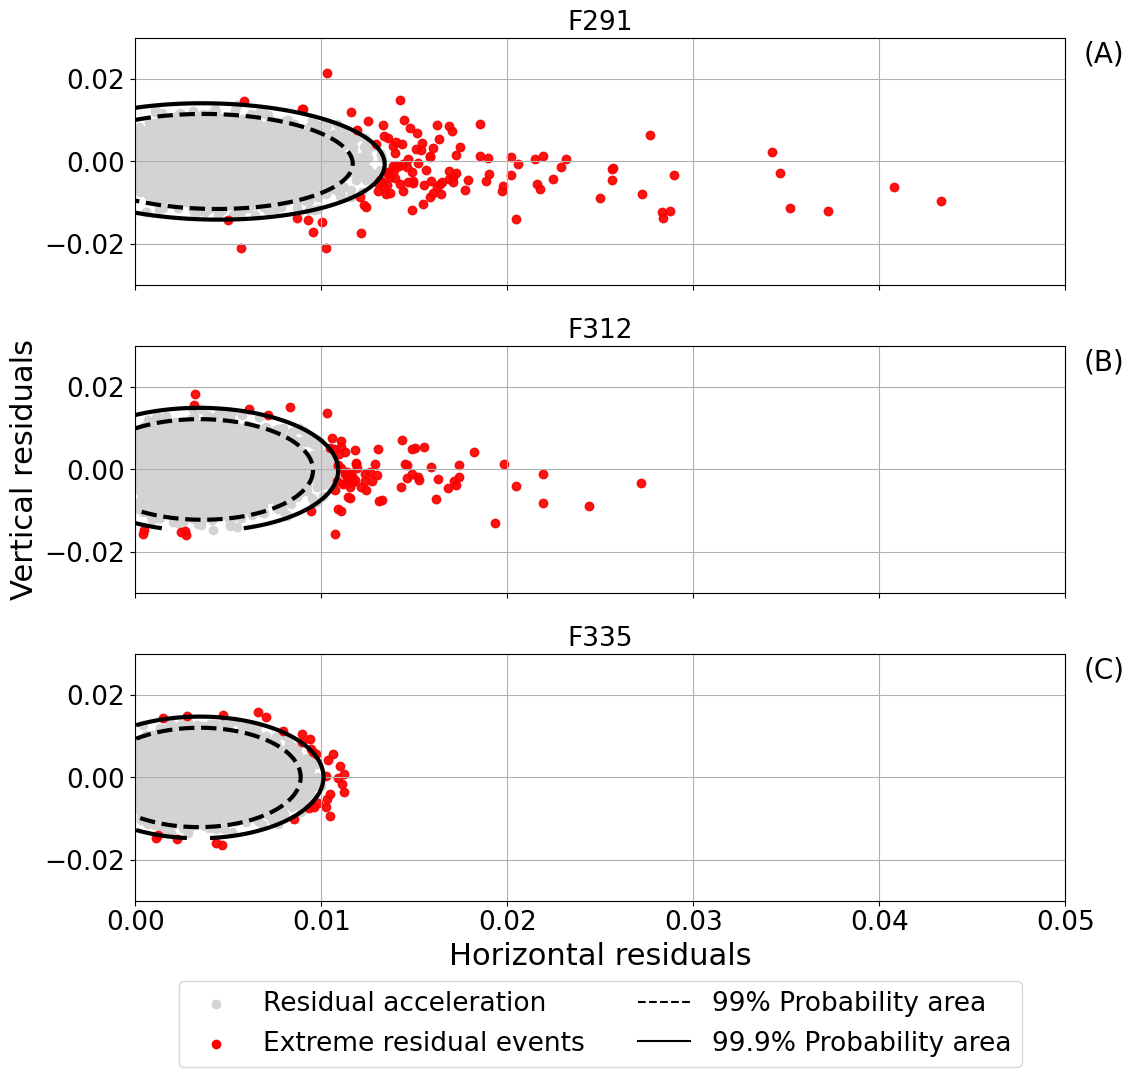

In [27]:

# We start by doing some general plot formatting
lab = ["(A)", "(B)", "(C)"]
fig, axs = plt.subplots(1,len(foi), sharey=True, sharex=True, figsize=((18,8)))
axs[0].set_ylabel("North-South residuals [m/s$^2$]")
axs[1].set_xlabel("East-West residuals [m/s$^2$]")

#Invisible markes for legend
axs[1].scatter([-10], [-10], color="lightgrey", label="Residual horizontal acceleration")
axs[1].scatter([-10], [-10], color="red", label="Extreme residual")
axs[1].plot([-10,-9], [-10,-9], color="black",linestyle="dashed", label= "99% Probability area")
axs[1].plot([-10,-9], [-10,-9], color="black", label="99.9% Probability area" )
axs[1].plot([-10, -9],[-10,-9], color="black", marker=r'$\rightarrow$',markersize=24,linewidth=0, label="Estimated north")
axs[1].plot([-10,-9], [-10,-9], color="black", linestyle="dashdot", alpha=0.7, label="IMU wave direction" )

dalpha = [7.01 * np.pi / 180, 5.56 *np.pi/180, 4.43 *np.pi/180]
for i in range(len(foi)):
  xlim = [-0.03, 0.03]
  ylim = [-0.05, 0.03]
  axs[i].text(-0.04,0.034,lab[i], fontsize=24)
  box = axs[i].get_position()
  axs[i].set_position([box.x0, box.y0+ 0.2, box.width , 0.8*box.height])

  aX = np.array(accx[i][:])
  aY = np.array(accy[i][:])
  filtx = filtfilt(b,a,aX)
  filty = filtfilt(b,a,aY)
  noiseX = aX - filtx
  noiseY = aY - filty
  generate_scatter_plots(noiseX, noiseY, axs[i],xlim, ylim)
  avg_u = np.average(filtx**2)
  avg_v = np.average(filty**2)
  m_ = np.sum((filty)*(filtx))/np.sum((filtx)**2)
  b_ = np.sum(filty - m_*filtx)/len(filtx)

  xvals_ = np.linspace(-0.05, 0.03, 500)
  y_x_linear = lambda x: m_*x + b_
  f_linear = lambda x: y_x_linear(x) - y_x_linear(0)
  axs[i].plot(xvals_, f_linear(xvals_), linestyle="dashdot", color="black", alpha=0.7)
  axs[i].arrow(0.015,0.015,-0.005*np.sin(dalpha[i]), 0.005*np.cos(dalpha[i]), color="black")

axs[1].legend(bbox_to_anchor=(0.5,-0.3), ncol=2, borderaxespad=0, loc="center")

plt.savefig("figures/figure_5.png")
plt.show()

fig, axs = plt.subplots(len(foi),1, sharey=True, sharex=True, figsize=((12,12)),gridspec_kw = {'wspace':0.05, 'hspace':0})
axs[1].set_ylabel("Vertical residuals")
axs[2].set_xlabel("Horizontal residuals")
axs[2].scatter([-10], [-10], color="lightgrey")
axs[2].scatter([-10], [-10], color="red")
axs[2].plot([-10,-9], [-10,-9], color="black", linestyle="dashed")
axs[2].plot([-10,-9], [-10,-9], color="black")

for i in range(len(foi)):
  axs[i].text(0.051,0.024,lab[i], fontsize=20)
  aX = np.array(accx[i][:])
  aY = np.array(accy[i][:])
  box = axs[i].get_position()
  axs[i].set_position([box.x0, box.y0+ 0.1, box.width , 0.8*box.height])
  filtx = filtfilt(b,a,aX)
  filty = filtfilt(b,a,aY)
  noiseX = aX - filtx
  noiseY = aY - filty
  noiseH = np.sqrt(noiseX**2 + noiseY**2)
  aZ = detrend(np.array(accz[i][:]))
  filtZ = filtfilt(b,a,detrend(np.array(accz[i][:])))
  noiseZ = aZ - filtZ
  
  title = generate_scatter_plots(noiseH, noiseZ, axs[i],xlim=[0,0.05], ylim=xlim)

axs[2].legend(["Residual acceleration", "Extreme residual events", "99% Probability area", "99.9% Probability area"],bbox_to_anchor=(0.5,-0.5), ncol=2, borderaxespad=0, loc="center")

plt.savefig("figures/figure_6.png")
plt.show()


We can plot the data points where the noise is sufficiently greater than the standard deviation of the noise. Here, we choose to plot the magnitude of the horizontal acceleration

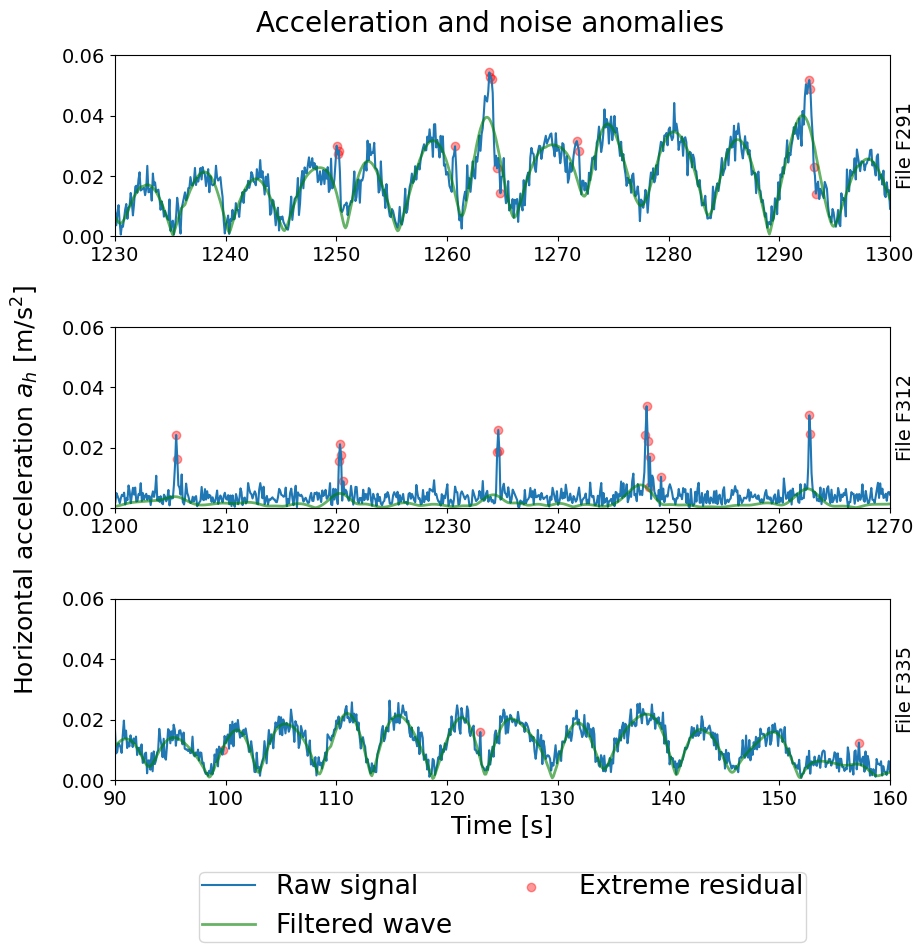

In [28]:
viewWindows = [[1230, 1300], [1200,1270], [90,160]]
viewWindowsY = [[0.0, 0.06], [0.0, 0.06], [0.0, 0.06]]
fig, axs = plt.subplots(3, figsize=(10,10))

# Point of interest. Will be used later.
poi = []


for i, file in enumerate(foi):
  aX = np.array(accx[i][:])
  aY = np.array(accy[i][:])

  filtx = filtfilt(b,a,aX)
  filty = filtfilt(b,a,aY)
  filtH = np.sqrt(filtx**2 + filty**2)  

  aH = np.sqrt(aX**2 + aY**2)

  noiseX = aX - filtx
  noiseY = aY - filty
  noiseH = np.sqrt(noiseX**2 + noiseY**2)

  x = np.block([[noiseX],[noiseY]]).T
  mu_hat = np.mean(x,0)
  sigma_hat = np.cov(x, rowvar=False)

  F = lambda x,y: (np.linalg.inv(sigma_hat)@(np.array([x-mu_hat[0], y- mu_hat[1]])))@(np.array([x-mu_hat[0], y- mu_hat[1]]))
  F = np.vectorize(F)

  axs[i].plot(t, aH[:Nt])
  axs[i].plot(t,filtH[:Nt], alpha=0.6, color="green", linewidth=2)

  poi.append(np.argwhere(F(noiseX,noiseY) > chi2.ppf(0.999,df=2)))

  for idx in poi[i]:
    axs[i].scatter(t[idx], aH[idx], alpha=0.4, color="red")

  axs[i].yaxis.set_label_position("right")
  axs[i].tick_params(axis='both', which='major', labelsize=14)
  axs[i].tick_params(axis='both', which='minor', labelsize=14)
  axs[i].set_ylabel(f"File F{file}", size=14)
  axs[i].set_xlim(viewWindows[i])
  axs[i].set_ylim(viewWindowsY[i])

  box = axs[i].get_position()
  axs[i].set_position([box.x0, box.y0+ 0.1, box.width , 0.8*box.height])

axs[-1].set_xlabel("Time [s]", size=18)
axs[2].legend(["Raw signal", "Filtered wave", "Extreme residual"], bbox_to_anchor=(0.5,-0.7), ncol=2, borderaxespad=0, borderpad=0.1, loc="center")

fig.supylabel("Horizontal acceleration $a_h$ [m/s$^2$]", size=18)
fig.suptitle("Acceleration and noise anomalies", size=20)

plt.savefig(f"detected_deviations.pdf")
plt.show()

## Are the collisions related to the wave signal? 
We perform a Hilbert transform of the data in order to determine if the anomalous spikes are phase locked with the wave signal. 

/tmp/ipykernel_18609/1186138641.py:12: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap('Set2')


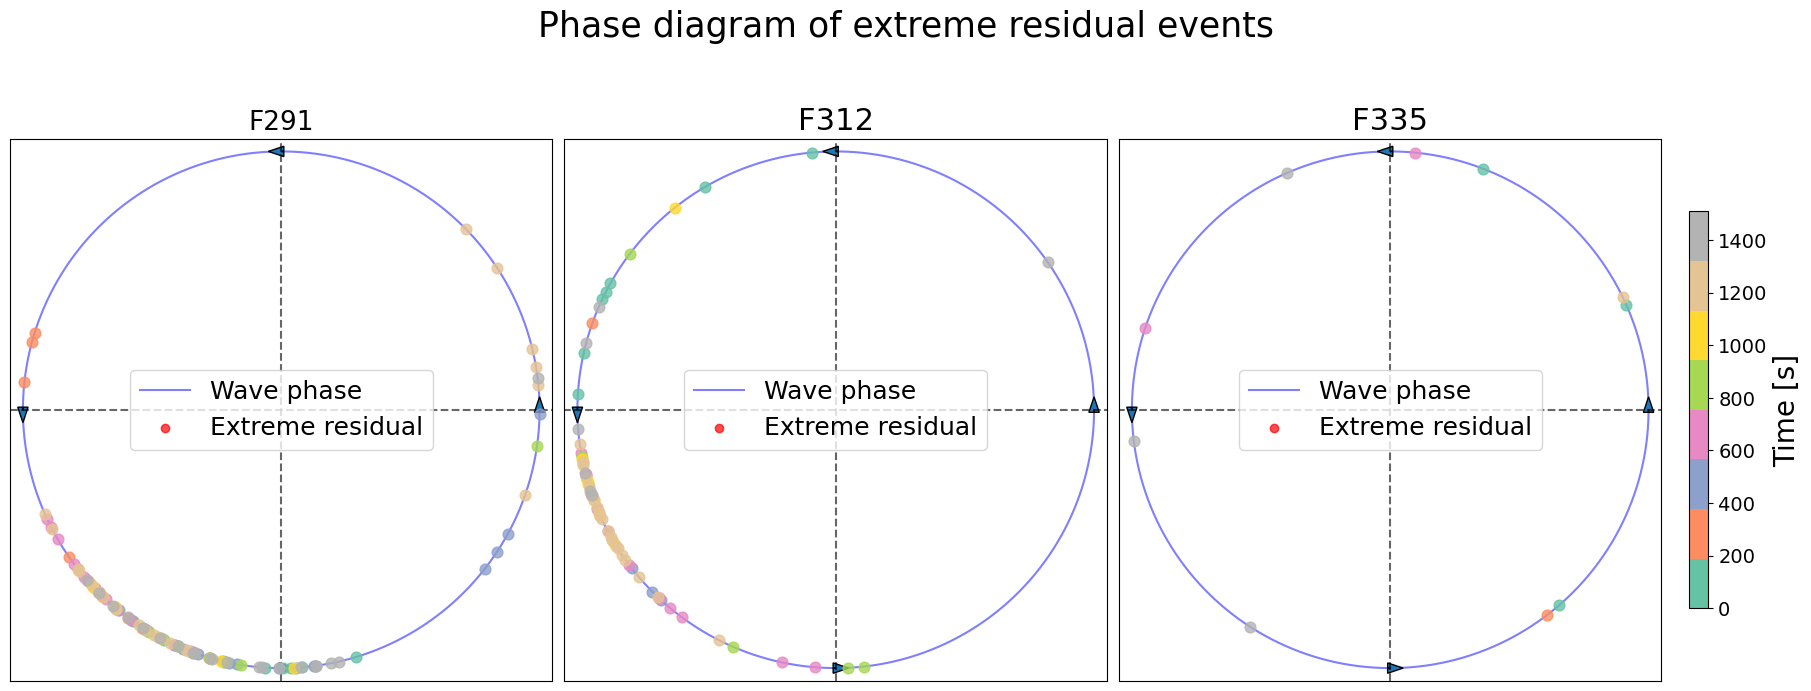

In [29]:
from scipy.signal import hilbert
from matplotlib.cm import get_cmap, ScalarMappable
from matplotlib.colors import Normalize

degs = np.linspace(-np.pi, np.pi, 10000)
fig, axs = plt.subplots(1,3, figsize=(18,10), layout='constrained', sharey=True)
axs[0].set_box_aspect(1)
axs[1].set_box_aspect(1)
axs[2].set_box_aspect(1)
x = np.cos(degs)
y = np.sin(degs)
cmap = get_cmap('Set2')
cols = cmap(np.linspace(0,1,len(t)))

for i in range(3):
  aX = np.array(accx[i][:])
  aY = np.array(accy[i][:])
  aH = np.sqrt(aX**2 + aY**2)[:Nt]
  filtx = filtfilt(b,a,aX)
  filty = filtfilt(b,a,aY)
  noiseX = aX - filtx
  noiseY = aY - filty
  axs[i].grid()
  x_ = np.block([[noiseX],[noiseY]]).T
  mu_hat = np.mean(x_,0)
  sigma_hat = np.cov(x_, rowvar=False)
  F = lambda x,y: (np.linalg.inv(sigma_hat)@(np.array([x-mu_hat[0], y- mu_hat[1]])))@(np.array([x-mu_hat[0], y- mu_hat[1]]))
  F = np.vectorize(F)
  analytic= hilbert(filty[:Nt])
  phase = np.angle(analytic)
  #poi = np.argwhere(F(noiseX,noiseY) > chi2.ppf(0.999,df=2))


  axs[i].plot(x,y, color="blue", alpha = 0.5, zorder=0)
  sigma4_marker = "s"
  # Trick for making legend
  axs[i].scatter(5*np.cos(phase[poi[i][0]]), 5*np.sin(phase[poi[i][0]]), color="red", alpha = 0.7, marker="o")
  for j,idx in enumerate(poi[i]):
    t_idx = np.argwhere(t==t[idx])
    axs[i].scatter(np.cos(phase[idx]), np.sin(phase[idx]), color=cols[t_idx], marker="o", alpha=0.8, s=60, zorder=5)
  

  axs[i].legend(["Wave phase", "Extreme residual"], fontsize=18)
  axs[i].plot(np.zeros(100), np.linspace(-1.1,1.1,100), linestyle="dashed", color="black", alpha=0.6)
  axs[i].plot(np.linspace(-1.1,1.1,100), np.zeros(100), linestyle="dashed", color="black", alpha=0.6)
  axs[i].set_xlim([-1.05, 1.05])
  axs[i].set_ylim([-1.05, 1.05])
  axs[i].set_title(f"F{foi[i]}")
  axs[i].set_xticks([])
  axs[i].set_yticks([])
  al = 0.05
  axs[i].arrow(1,0,0,al, width =0.002,  length_includes_head=True, head_width =0.04)
  axs[i].arrow(0,1,-al,0, width =0.002, length_includes_head=True, head_width =0.04)
  axs[i].arrow(-1,0,0,-al, width =0.002, length_includes_head=True, head_width =0.04)
  axs[i].arrow(0,-1,al,0, width =0.002, length_includes_head=True, head_width =0.04)
  plt.rcParams['axes.labelsize'] = 20
  plt.rcParams['axes.titlesize'] = 22
  plt.rcParams['xtick.labelsize'] = 14
  plt.rcParams['ytick.labelsize'] = 14

fig.suptitle("Phase diagram of extreme residual events", y=0.90)
cbar = fig.colorbar(ScalarMappable(Normalize(vmin=0, vmax=t[-1]), cmap=cmap), ax=axs[2], orientation='vertical', label="Time [s]", shrink=0.4)

plt.savefig("figures/phase_diagram.png")
plt.show()

# Computing wave statistics

The ice floes are being accelerated by the underlying wave field, and hence it is aluable to investigate the possible link between wave statistics and the collisions. These statistics are computed by a double fourier transform of the acceleration to get the surface elevation $\eta$, and the exact algorithms are both explained in PAPER, and shown in the ```analyse_imu```-function. Here, we plot the wavestatistics with the files of interest marked with green lines.  

0.021694931785649196
0.029332305417237012
0.5171608187230883
0.02863445102497603
23.405714285714286
24.094117647058823
10.922666666666666
14.124137931034483


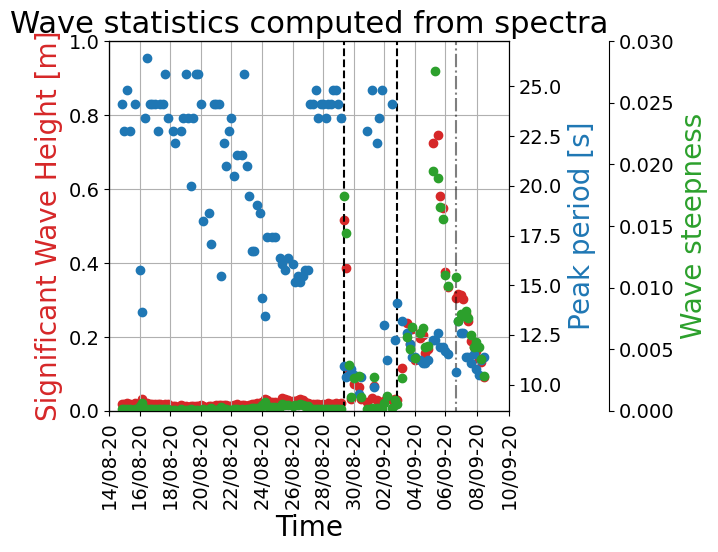

In [30]:
fig, ax1 = plt.subplots()
fig.subplots_adjust(right=0.75)
times = np.zeros(stop-start + 1)
for i in range(stop - start + 1):
    times[i] = 4.*i + 20 #Four hours between measurements, starts at t=20 hours. 
    if start + i in foi[:-1]:
        ax1.plot(times[i]*np.ones(600), np.linspace(-0.4, 4, 600), linestyle="dashed", color="black")
    elif start + i == foi[-1]:
        ax1.plot(times[i]*np.ones(600), np.linspace(-0.4, 4, 600), linestyle="dashdot", color="black", alpha=0.5)
        
print(SWH[290-start])
print(SWH[310-start])
print(SWH[291-start])
print(SWH[312-start])
print(Tp[290-start])
print(Tp[310-start])

print(Tp[291-start])
print(Tp[312-start])

ax1.set_xlabel("Time")
ax1.scatter(times[Tp <= 30], SWH[Tp <= 30], color="tab:red")
ax1.scatter(times[Tp > 30], SWH[Tp > 30], color="tab:red", alpha=0.6)
ax2 = ax1.twinx()

ax2.scatter(times[Tp <= 30], Tp[Tp <= 30], color="tab:blue", alpha=1)
ax2.scatter(times[Tp > 30], Tp[Tp > 30], color="tab:blue", alpha=0.6)

ax3 = ax1.twinx()
ax3.spines.right.set_position(("axes", 1.25))
ax3.scatter(times[Tp <= 30], ak[Tp <= 30], color="tab:green")
ax3.scatter(times[Tp > 30],  ak[Tp > 30], color="tab:green", alpha=0.6)
ax1.set_ylabel("Significant Wave Height [m]", color="tab:red")
ax2.set_ylabel("Peak period [s]", color="tab:blue")
ax3.set_ylabel("Wave steepness", color="tab:green")
ax3.set_ylim([0,0.03])
ax1.set_ylim([0, 1])
ax1.set_xlim([times[0], times[-1]+5])
ax1.set_xticks([0,48,96, 144, 192,240, 288, 336, 384, 432, 480, 528, 578, 628], \
           labels=["14/08-20", "16/08-20", "18/08-20", "20/08-20","22/08-20", "24/08-20", "26/08-20",  "28/08-20", "30/08-20",
                   "02/09-20",  "04/09-20", "06/09-20", "08/09-20", "10/09-20"], rotation=90)
ax1.grid()
ax1.set_title("Wave statistics computed from spectra")
plt.savefig("figures/wavestat_graph.pdf", bbox_inches="tight")
plt.show()

